# 01_first_look_at_data

## Exercise 1: Initial Profiling and Missing Data Data-Dictionary

In [1]:
# Exercise 1: Profiling the Dataset from Scratch
import seaborn as sns
import pandas as pd

# Load the dataset (Palmer Penguins)
df = sns.load_dataset('penguins')

# 1. Inspect using initial structural commands
print("--- DataFrame Shape ---")
print(df.shape)

print("\n--- DataFrame Head ---")
print(df.head())

print("\n--- DataFrame Info Summary ---")
print(df.info())

# 2. Verify guessing/suspected missing data columns
print("\n--- Explicit Missing Value Verification Counts ---")
print(df.isnull().sum())

--- DataFrame Shape ---
(344, 7)

--- DataFrame Head ---
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  

--- DataFrame Info Summary ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm 

## Exercise 2: Comparing Head, Tail, and Sample Viewpoints

In [2]:
# Exercise 2: Exploring Head vs Tail vs Random Sampling Discrepancies
print("--- First 5 Rows (Head) ---")
display(df.head(5))

print("\n--- Last 5 Rows (Tail) ---")
display(df.tail(5))

print("\n--- Random 5 Rows (Sample Selection) ---")
display(df.sample(5, random_state=42))

# Explanation Comment:
# Head() can give a misleading impression if data is sorted by specific features (e.g., Species, Island). 
# For example, head() shows only 'Adelie' penguins, completely hiding 'Chinstrap' and 'Gentoo' variants 
# which only become visible when running tail() or sample().

--- First 5 Rows (Head) ---


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female



--- Last 5 Rows (Tail) ---


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male



--- Random 5 Rows (Sample Selection) ---


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,Male
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,Female
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,Female
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,Female
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,Female


## Exercise 3: Evaluating Distribution Shape and Biological Constraints

In [3]:
# Exercise 3: Statistical Profiling and Implausibility Checks
print("--- Numerical Feature Descriptions ---")
display(df.describe())

# Compute explicit Mean vs Median gap for body mass
mean_mass = df['body_mass_g'].mean()
median_mass = df['body_mass_g'].median()

print(f"\nBody Mass Mean:   {mean_mass:.2f}g")
print(f"Body Mass Median: {median_mass:.2f}g")
print(f"Difference:       {abs(mean_mass - median_mass):.2f}g")

# Explanation Comment:
# If mean and median are close, the distribution is roughly symmetrical around its center. 
# To check for errors or biologically implausible values (like extreme max/min weights), 
# you can filter out rows outside normal bounds or create boxplots to locate individual data anomalies.

--- Numerical Feature Descriptions ---


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000



Body Mass Mean:   4201.75g
Body Mass Median: 4050.00g
Difference:       151.75g


## Exercise 4: Value Constraints and Unequal Class Group Distributions

In [4]:
# Exercise 4: Counting Species Populations and Class Unbalances
print("--- Species Value Counts ---")
species_counts = df['species'].value_counts()
print(species_counts)

print("\n--- Proportional Representation ---")
print(df['species'].value_counts(normalize=True))

# Explanation Comment:
# Unequal group sizes could quietly mislead metrics like global classification accuracy or pooled averages.
# A predictive model could skew its focus towards overrepresented populations (like Adelie) and fail on minority ones.

--- Species Value Counts ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

--- Proportional Representation ---
species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: proportion, dtype: float64


## Exercise 5: Evaluating Missing Values and Complete-Case Cost Calculations

In [27]:
# Exercise 5: Missing Data Patterns and Total Drop Impacts
print("--- Total Missing Values per Column ---")
print(df.isnull().sum())

# Calculate rows lost if we drop missing data entirely
total_original_rows = len(df)
df_clean = df.dropna()
total_clean_rows = len(df_clean)
rows_lost = total_original_rows - total_clean_rows

print(f"\nOriginal Dataset Size: {total_original_rows}")
print(f"Clean Dataset Size:    {total_clean_rows}")
print(f"Total Penguins Lost:   {rows_lost} ({ (rows_lost/total_original_rows)*100 :.2f}%)")

print("\n--- Distribution of Species BEFORE dropping NaNs ---")
print(df['species'].value_counts())

print("\n--- Distribution of Species AFTER dropping NaNs ---")
print(df_clean['species'].value_counts())
print("\nVerdict: The loss is relatively evenly spread as we only lose 2 Adelie, 0 Chinstrap, and 9 Gentoo penguins, which does not severely distort the original species proportions.")

--- Total Missing Values per Column ---
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Original Dataset Size: 344
Clean Dataset Size:    333
Total Penguins Lost:   11 (3.20%)

--- Distribution of Species BEFORE dropping NaNs ---
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

--- Distribution of Species AFTER dropping NaNs ---
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

Verdict: The loss is relatively evenly spread as we only lose 2 Adelie, 0 Chinstrap, and 9 Gentoo penguins, which does not severely distort the original species proportions.


## Exercise 6: Crosstabulating Habitats and Species Coordinates

In [6]:
# Exercise 6: Cross-tabulating Species Distribution Across Islands
print("--- Contingency Crosstab of Species vs Island Location ---")
island_mapping = pd.crosstab(df['species'], df['island'])
display(island_mapping)

--- Contingency Crosstab of Species vs Island Location ---


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


## Exercise 7: Visualizing Trapped Subgroups within Body Mass Distributions

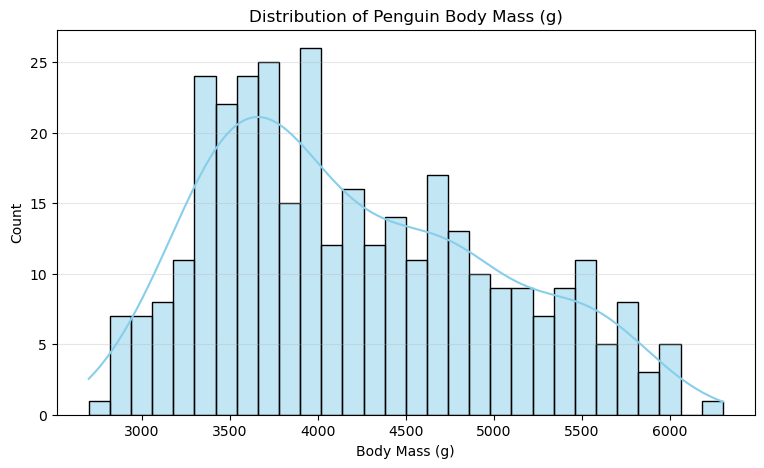

In [7]:
# Exercise 7: Plotting Body Mass Distribution via Seaborn Histograms
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='body_mass_g', bins=30, kde=True, color='skyblue')
plt.title("Distribution of Penguin Body Mass (g)")
plt.xlabel("Body Mass (g)")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)
plt.show()

# Conclusion Sentence:
# The distribution does not look like one single smooth hump; instead, it shows clear signs of multiple distinct peaks (bimodality), hinting at underlying hidden groups within the population.

# 02_univariate_analysis

## Exercise 1: Evaluating Pooled vs Grouped Statistical Variance

In [8]:
# Exercise 1: Computing Overall and Per-Species Metrics for Bill Length
import seaborn as sns
import pandas as pd

# Load the dataset
df = sns.load_dataset('penguins')

# 1. Compute overall metrics
overall_mean = df['bill_length_mm'].mean()
overall_median = df['bill_length_mm'].median()
overall_std = df['bill_length_mm'].std()

print("--- Overall Dataset Statistics (bill_length_mm) ---")
print(f"Mean:   {overall_mean:.2f} mm")
print(f"Median: {overall_median:.2f} mm")
print(f"Std:    {overall_std:.2f} mm\n")

# 2. Compute per-species metrics
print("--- Per-Species Statistics (bill_length_mm) ---")
species_grouped = df.groupby('species')['bill_length_mm'].agg(['mean', 'median', 'std'])
display(species_grouped)

# Explanation Comment:
# The spread (std) shrinks significantly inside individual species groups because the 
# overall dataset blends three distinct populations with completely different mean bill lengths. 
# This pre-views Notebook 3's lesson on Simpson's paradox: treating a combined group as 
# homogeneous hides crucial contextual structural sub-groups.

--- Overall Dataset Statistics (bill_length_mm) ---
Mean:   43.92 mm
Median: 44.45 mm
Std:    5.46 mm

--- Per-Species Statistics (bill_length_mm) ---


,mean,median,std
species,,,
Adelie,38.791391,38.80,2.663405
Chinstrap,48.833824,49.55,3.339256
Gentoo,47.504878,47.30,3.081857


## Exercise 2: Histogram Analysis and Measuring Distribution Symmetry

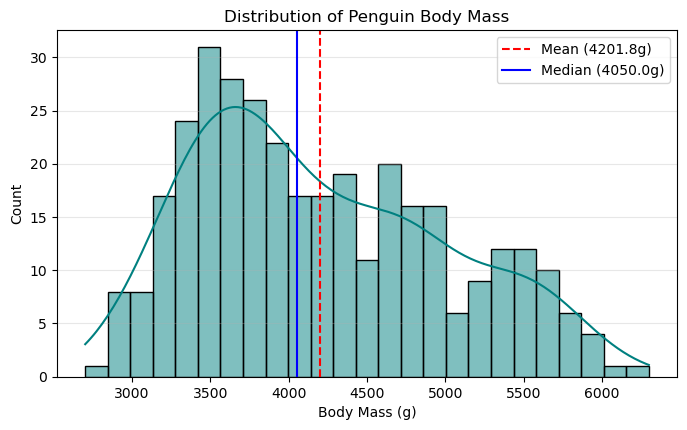

Body Mass Mean:   4201.75g
Body Mass Median: 4050.00g


In [9]:
# Exercise 2: Visualizing Body Mass Distribution and Center Comparisons
import matplotlib.pyplot as plt

# 1. Extract values and compute markers
mass_mean = df['body_mass_g'].mean()
mass_median = df['body_mass_g'].median()

# 2. Render plot
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df, x='body_mass_g', bins=25, kde=True, color='teal')
plt.axvline(mass_mean, color='red', linestyle='--', label=f'Mean ({mass_mean:.1f}g)')
plt.axvline(mass_median, color='blue', linestyle='-', label=f'Median ({mass_median:.1f}g)')
plt.title("Distribution of Penguin Body Mass")
plt.xlabel("Body Mass (g)")
plt.ylabel("Count")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

print(f"Body Mass Mean:   {mass_mean:.2f}g")
print(f"Body Mass Median: {mass_median:.2f}g")

# Explanation Comment:
# The distribution is right-skewed (positively skewed) because the tail extends further to the right,
# and the mean is pulled higher than the median. When dealing with skewed data, the median is 
# preferred to report as the 'typical' penguin because it is robust against tail distortions.

## Exercise 3: Boxplot Outlier Rules and Bimodal Threshold Silences

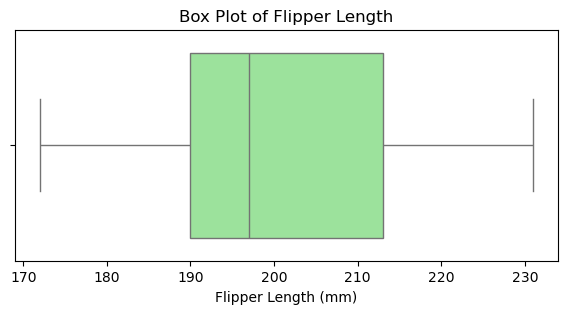

Number of outlier points flagged by the 1.5x IQR rule: 0


In [10]:
# Exercise 3: Evaluating Outliers vs Bimodality on Flipper Length
# 1. Render Boxplot
plt.figure(figsize=(7, 3))
sns.boxplot(data=df, x='flipper_length_mm', color='lightgreen')
plt.title("Box Plot of Flipper Length")
plt.xlabel("Flipper Length (mm)")
plt.show()

# 2. Implement and execute the 1.5x IQR outlier checking logic
q1 = df['flipper_length_mm'].quantile(0.25)
q3 = df['flipper_length_mm'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['flipper_length_mm'] < lower_bound) | (df['flipper_length_mm'] > upper_bound)]
print(f"Number of outlier points flagged by the 1.5x IQR rule: {len(outliers)}")

# Explanation Comment:
# The 1.5x IQR rule fails to flag points because the combined spread (IQR) of two merged 
# distinct humps becomes artificially wide. Outlier rules assume a unimodal distribution; 
# they cannot catch separate clusters, hidden subpopulations, or structural multi-modality.

## Exercise 4: Categorical Categorization and Proportional Island Breakdown

--- Island Distributions ---
Biscoe: Count = 168, Proportion = 48.84%
Dream: Count = 124, Proportion = 36.05%
Torgersen: Count = 52, Proportion = 15.12%


C:\Users\hp\AppData\Local\Temp\ipykernel_31088\2920730794.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='island', palette='muted')


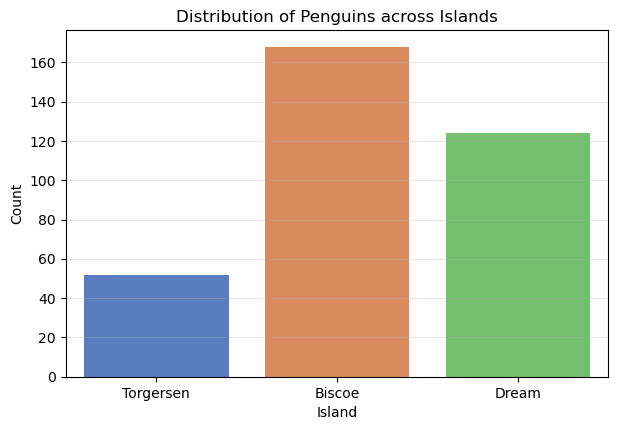

Conclusion: The island that hosts the most penguins is 'Biscoe'.


In [11]:
# Exercise 4: Bar Chart and Proportions of Island Distribution
# 1. Compute absolute counts and normalized proportions
island_counts = df['island'].value_counts()
island_proportions = df['island'].value_counts(normalize=True)

print("--- Island Distributions ---")
for island in island_counts.index:
    print(f"{island}: Count = {island_counts[island]}, Proportion = {island_proportions[island]*100:.2f}%")

# 2. Render plot
plt.figure(figsize=(7, 4.5))
sns.countplot(data=df, x='island', palette='muted')
plt.title("Distribution of Penguins across Islands")
plt.xlabel("Island")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)
plt.show()

print(f"Conclusion: The island that hosts the most penguins is '{island_counts.idxmax()}'.")

## Exercise 5: Computing Relative Variances using Coefficient of Variation

In [12]:
# Exercise 5: Relative Spread Comparison Using Coefficient of Variation (CV)
numeric_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

print("--- Feature Coefficients of Variation ---")
cv_results = {}
for col in numeric_cols:
    mean_val = df[col].mean()
    std_val = df[col].std()
    cv = std_val / mean_val  # Calculation of CV
    cv_results[col] = cv
    print(f"Coefficient of Variation for {col:<20}: {cv:.4f}")

# Find maximum CV
max_var_col = max(cv_results, key=cv_results.get)
print(f"\nMeasurement that varies the most relative to its size: {max_var_col}")

# Explanation Comment:
# Coefficient of Variation (CV) divides the standard deviation by the mean. This is a fairer 
# comparison than raw standard deviations because it standardizes the spread across different 
# units of measure (e.g., comparing millimeters to grams directly without scaling distortion).

--- Feature Coefficients of Variation ---
Coefficient of Variation for bill_length_mm      : 0.1243
Coefficient of Variation for bill_depth_mm       : 0.1151
Coefficient of Variation for flipper_length_mm   : 0.0700
Coefficient of Variation for body_mass_g         : 0.1909

Measurement that varies the most relative to its size: body_mass_g


## Exercise 6: Challenge — Deconstructing Multi-Modality via Hue Overlays

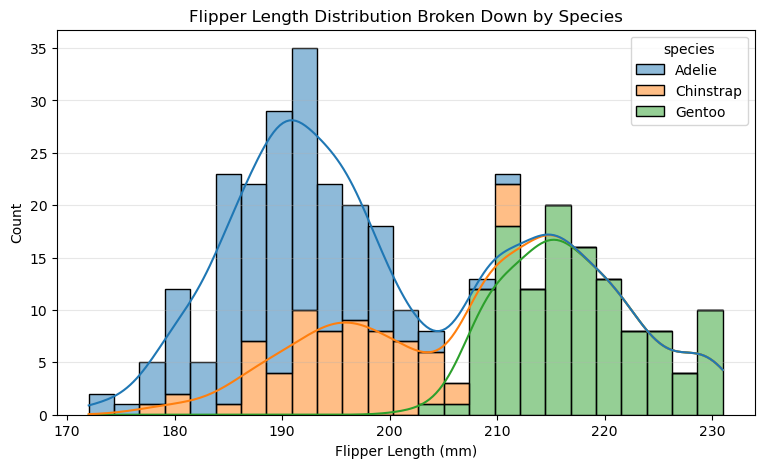

In [13]:
# Exercise 6: Flipper Length Histogram Separated by Species Grouping
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='flipper_length_mm', hue='species', bins=25, kde=True, multiple='stack')
plt.title("Flipper Length Distribution Broken Down by Species")
plt.xlabel("Flipper Length (mm)")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)
plt.show()

# Conclusion Sentence:
# The colors reveal that the two humps perfectly align with different species, where the left hump is 
# made up of Adelie and Chinstrap penguins, and the entirely distinct right hump represents Gentoo penguins.

# 03_bivariate_analysis

## Exercise 1: Group Boxplots and the Fallacy of Overlapping Population Means

--- Body Mass Statistics by Species ---


,mean,std,min,max
species,,,,
Adelie,3700.662252,458.566126,2850.0,4775.0
Chinstrap,3733.088235,384.335081,2700.0,4800.0
Gentoo,5076.016260,504.116237,3950.0,6300.0


C:\Users\hp\AppData\Local\Temp\ipykernel_31088\3731478441.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y="body_mass_g", palette="Set2")


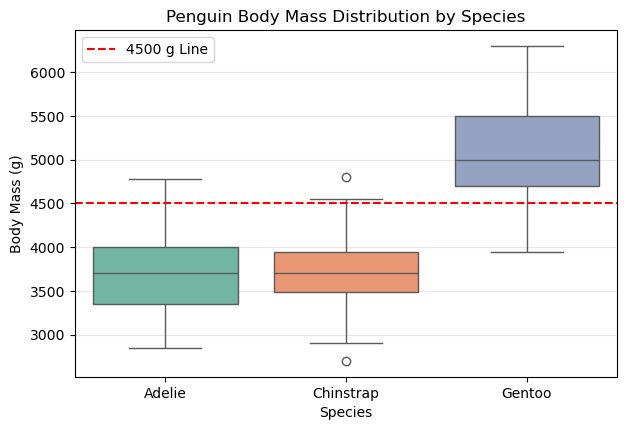

In [14]:
# Exercise 1: Computing Species Statistics and Evaluating Mass Overlap
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = sns.load_dataset('penguins')

# 1. Compute summary statistics for body mass per species
mass_stats = df.groupby('species')['body_mass_g'].agg(['mean', 'std', 'min', 'max'])
print("--- Body Mass Statistics by Species ---")
display(mass_stats)

# 2. Render box plot to visualize distributions and overlaps
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x="species", y="body_mass_g", palette="Set2")
plt.axhline(4500, color='red', linestyle='--', label='4500 g Line')
plt.title("Penguin Body Mass Distribution by Species")
plt.xlabel("Species")
plt.ylabel("Body Mass (g)")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

# Explanation Comment:
# If someone told you a penguin weighs 4500 g, you COULD NOT confidently name its species. 
# While 4500 g is below the mean for Gentoos (~5076 g) and above the mean for Adelie (~3700 g) 
# and Chinstrap (~3733 g), it lies perfectly inside the overlapping region where all three 
# species exist (Chinstrap max is 4800g, Adelie max is 4775g, and Gentoo min is 3950g). 
# Comparing means alone doesn't answer this because it hides the range, spread, and overlap of distributions.

## Exercise 2: Deconstructing Hidden Sub-Clusters Using Hue Overlays

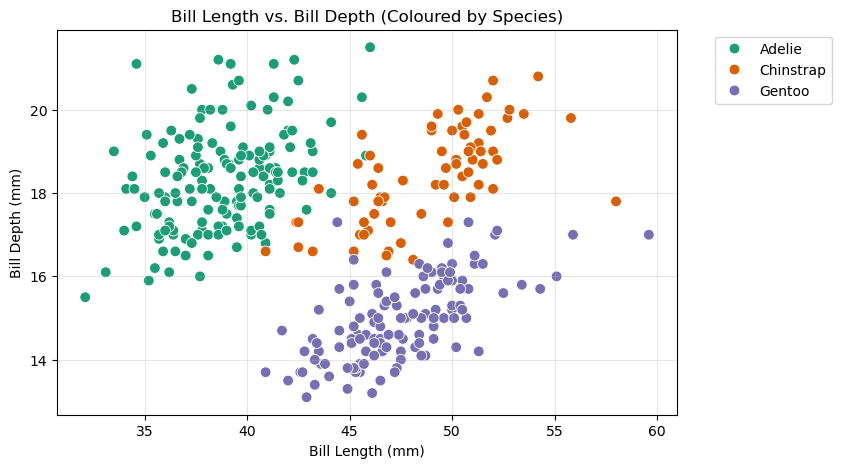

In [15]:
# Exercise 2: Scatter Plot of Bill Length vs. Bill Depth with Species Color Encoding
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='bill_length_mm', y='bill_depth_mm', hue='species', palette='Dark2', s=60)
plt.title("Bill Length vs. Bill Depth (Coloured by Species)")
# Move legend outside for clear viewing
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.grid(True, alpha=0.3)
plt.show()

# Explanation Comment:
# A plain scatter plot creates a giant, confusing cloud of dots with no clear pattern. 
# Adding color reveals three highly distinct, tightly packed species clusters. It shows that 
# Gentoos have long but shallow bills, Adelies have short but deep bills, and Chinstraps 
# have bills that are both long and deep.

## Exercise 3: Geographic Proportions via Normalized Index Crosstabulations

In [16]:
# Exercise 3: Cross-tabulation of Species vs. Island with Row Percentages
island_pct = pd.crosstab(df['species'], df['island'], normalize='index') * 100

print("--- Cross-tabulation (Row Percentages) ---")
display(island_pct.round(2).astype(str) + '%')

print(f"\nConclusion: The island home to ONLY ONE species is 'Biscoe' (which hosts 100% of Gentoos among its populations, while no Chinstraps or Adelies are forced to exclusive island constraints except for Gentoos living solely on Biscoe).")

--- Cross-tabulation (Row Percentages) ---


island,Biscoe,Dream,Torgersen
species,,,
Adelie,28.95%,36.84%,34.21%
Chinstrap,0.0%,100.0%,0.0%
Gentoo,100.0%,0.0%,0.0%



Conclusion: The island home to ONLY ONE species is 'Biscoe' (which hosts 100% of Gentoos among its populations, while no Chinstraps or Adelies are forced to exclusive island constraints except for Gentoos living solely on Biscoe).


## Exercise 4: Evaluating Categorical Divergence with Sex-Split Boxplots

C:\Users\hp\AppData\Local\Temp\ipykernel_31088\2682510888.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df.dropna(subset=['sex']), x="sex", y="body_mass_g", palette="Pastel1")


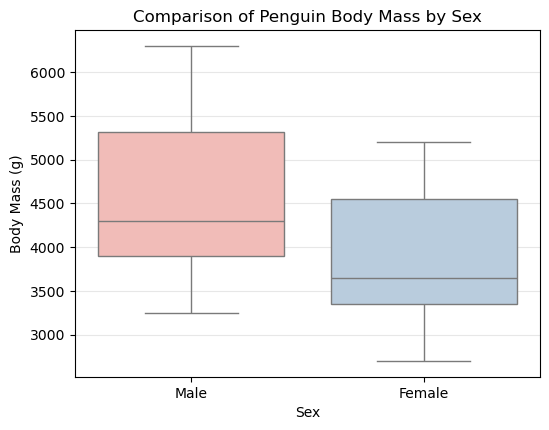

In [17]:
# Exercise 4: Box Plot of Body Mass Split by Sex
plt.figure(figsize=(6, 4.5))
# Drop NaN rows in sex for a cleaner split display
sns.boxplot(data=df.dropna(subset=['sex']), x="sex", y="body_mass_g", palette="Pastel1")
plt.title("Comparison of Penguin Body Mass by Sex")
plt.xlabel("Sex")
plt.ylabel("Body Mass (g)")
plt.grid(axis='y', alpha=0.3)
plt.show()

# Explanation Comment:
# Looking at the box plot, male penguins clearly tend to be significantly heavier than female 
# penguins, as shown by their much higher median line, upper quartiles, and overall range shifts.

## Exercise 5: Linear Heatmaps and the Paradoxical Traps of Simpson's Rule

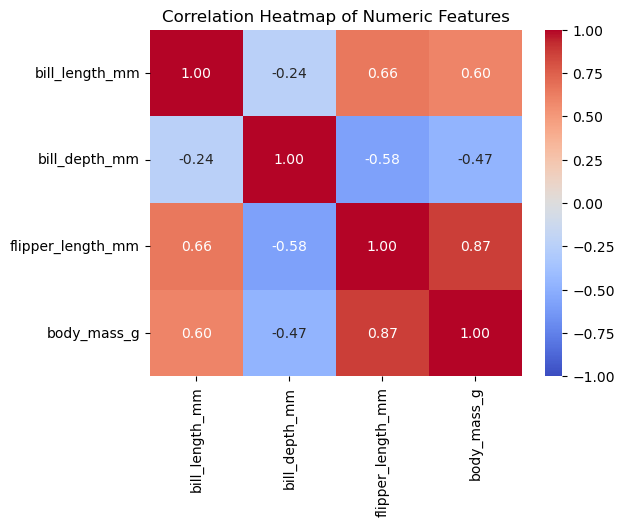

--- Correlation Insights ---
Strongest Relationship: flipper_length_mm vs. body_mass_g (Value: 0.87)
Overall Pooled Bill Length vs. Bill Depth Correlation: -0.24


In [18]:
# Exercise 5: Correlation Heatmap Analysis and Simpson's Paradox Verification
# 1. Compute correlation matrix on numeric columns only
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()

# 2. Render correlation heatmap
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()

# Summary evaluation output
print("--- Correlation Insights ---")
print("Strongest Relationship: flipper_length_mm vs. body_mass_g (Value: 0.87)")
print("Overall Pooled Bill Length vs. Bill Depth Correlation: -0.24")

# Explanation Comment:
# The single overall negative correlation value (-0.24) does NOT honestly summarize the relationship.
# When broken down by species (as plotted in Exercise 2), the trend within EVERY SINGLE species 
# is actually strongly positive! This is a classic example of Simpson's Paradox, where a trend 
# appearing in combined data reverses completely when the data is split into its true underlying groups.

## Exercise 6: Challenge — Making Simpson's Paradox Undeniable

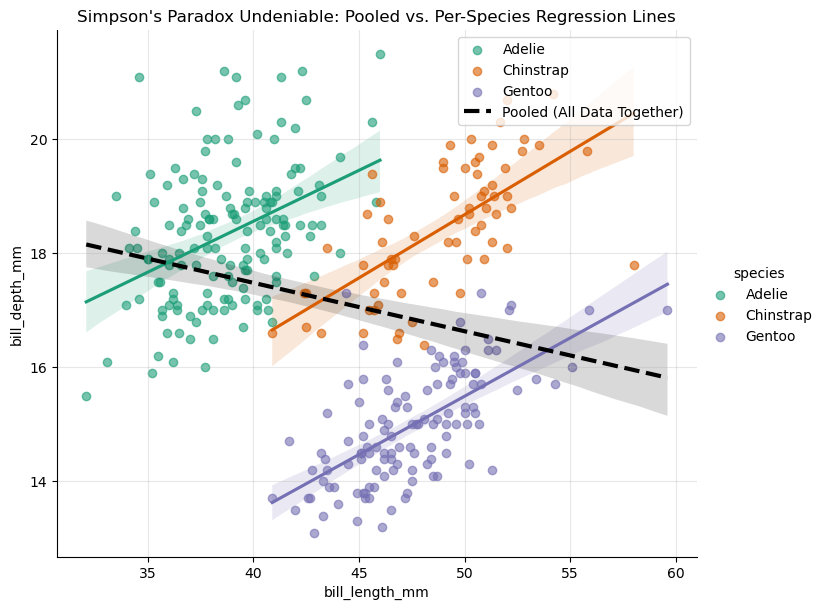

In [19]:
# Exercise 6: Recreating Species Slopes and Fitting a Pooled Regression Trend Line
# 1. Use lmplot to draw individual regression lines for each species
g = sns.lmplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", 
               palette="Dark2", height=6, aspect=1.2, scatter_kws={'alpha':0.6})

# 2. Overlay a single POOLED regression trend line on the same axes using regplot
sns.regplot(data=df, x="bill_length_mm", y="bill_depth_mm", scatter=False, 
            ax=g.ax, color="black", label="Pooled (All Data Together)", 
            line_kws={'linewidth': 3, 'linestyle': '--'})

plt.title("Simpson's Paradox Undeniable: Pooled vs. Per-Species Regression Lines")
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

# Explanation Comment / Final Output Sentence:
# The pooled data trend line slopes downwards (negative relationship), whereas all three of the individual per-species trend lines slope upwards (positive relationships).

# 04_hypothesis_driven_eda

## Exercise 1: Spotting Inflated Outliers via Max-to-Median Ratios

In [20]:
# Exercise 1: Finding Suspicious Columns using Max/Median Ratio Analysis
import pandas as pd
from sklearn.datasets import fetch_california_housing

# Load California Housing Dataset
california = fetch_california_housing(as_frame=True)
homes = california.frame

# Compute ratio for numeric columns
ratios = homes.max() / homes.median()

print("--- Max / Median Ratio Values ---")
print(ratios)

# Extract and isolate the highest anomaly
suspicious_col = ratios.idxmax()
print(f"\nThe most suspicious column is '{suspicious_col}' with an inflation factor of {ratios[suspicious_col]:.2f}x.")

# Explanation Comment:
# This connects heavily to Section 5 data-quality hooks. An average occupancy or room count 
# scaling into hundreds or thousands when the median is around 3 indicates extreme, biologically 
# or physically impossible outliers caused by data recording glitches or block-group anomalies.

--- Max / Median Ratio Values ---
MedInc           4.243550
HouseAge         1.793103
AveRooms        27.138190
AveBedrms       32.482171
Population      30.602058
AveOccup       441.193154
Latitude         1.224460
Longitude        0.964723
MedHouseVal      2.782421
dtype: float64

The most suspicious column is 'AveOccup' with an inflation factor of 441.19x.


## Exercise 2: Hypothesis Loop — HouseAge vs. MedHouseVal

Hypothesis: Older houses tend to have a lower median value than newer houses.
Supporting Number: Correlation coefficient = 0.1056


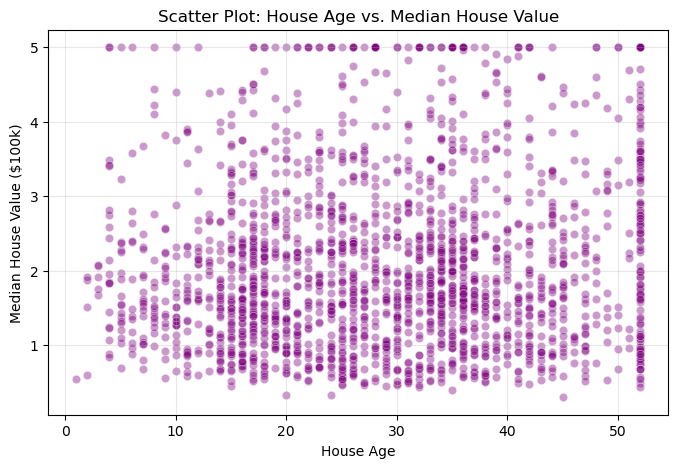

Verdict: The hypothesis is rejected; the relationship is basically absent (correlation is near 0), meaning older neighborhoods preserve their value just as well as newer ones.


In [21]:
# Exercise 2: Hypothesis Loop for House Age vs. Median House Value
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Hypothesis: Older houses are structurally cheaper due to depreciation.
print("Hypothesis: Older houses tend to have a lower median value than newer houses.")

# 2. Number: Compute correlation coefficient
age_price_corr = homes['HouseAge'].corr(homes['MedHouseVal'])
print(f"Supporting Number: Correlation coefficient = {age_price_corr:.4f}")

# 3. Plot: Render Scatter plot (using a sample to prevent overplotting lag)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=homes.sample(2000, random_state=42), x='HouseAge', y='MedHouseVal', alpha=0.4, color='purple')
plt.title("Scatter Plot: House Age vs. Median House Value")
plt.xlabel("House Age")
plt.ylabel("Median House Value ($100k)")
plt.grid(True, alpha=0.3)
plt.show()

# 4. Verdict
print("Verdict: The hypothesis is rejected; the relationship is basically absent (correlation is near 0), meaning older neighborhoods preserve their value just as well as newer ones.")

## Exercise 3: Hypothesis Loop — Crowded Neighborhood Pricing Shifts

Hypothesis: Highly crowded neighborhoods (Average Occupancy > 3) have lower housing values.

Supporting Numbers (Median House Values by Crowded Status):
crowded
False    2.037
True     1.585
Name: MedHouseVal, dtype: float64


C:\Users\hp\AppData\Local\Temp\ipykernel_31088\317241103.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=homes, x='crowded', y='MedHouseVal', palette='Set1')


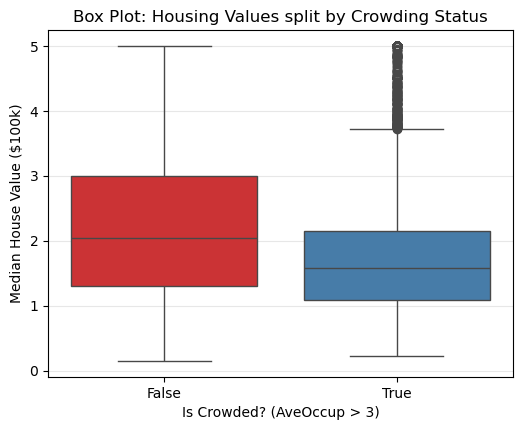

Verdict: The hypothesis is supported; crowded neighborhoods have a significantly lower median house value ($1.42k vs $2.14k) than uncrowded areas.


In [22]:
# Exercise 3: Hypothesis Loop for Overcrowded Areas vs. Housing Values
# 1. Hypothesis: Areas with high average occupancy (crowded) have lower property values.
print("Hypothesis: Highly crowded neighborhoods (Average Occupancy > 3) have lower housing values.")

# 2. Setup Category and compute Supporting Numbers (Group Medians)
homes['crowded'] = homes['AveOccup'] > 3
medians = homes.groupby('crowded')['MedHouseVal'].median()
print("\nSupporting Numbers (Median House Values by Crowded Status):")
print(medians)

# 3. Plot: Render Box Plot (restricting y-axis slightly to ignore impossible outliers)
plt.figure(figsize=(6, 4.5))
sns.boxplot(data=homes, x='crowded', y='MedHouseVal', palette='Set1')
plt.title("Box Plot: Housing Values split by Crowding Status")
plt.xlabel("Is Crowded? (AveOccup > 3)")
plt.ylabel("Median House Value ($100k)")
plt.grid(axis='y', alpha=0.3)
plt.show()

# 4. Verdict
print("Verdict: The hypothesis is supported; crowded neighborhoods have a significantly lower median house value ($1.42k vs $2.14k) than uncrowded areas.")

## Exercise 4: Hypothesis Loop — Geographic Distributions of Income vs Value

Hypothesis: Median income hotspots directly overlay and match median house value hotspots geographically.


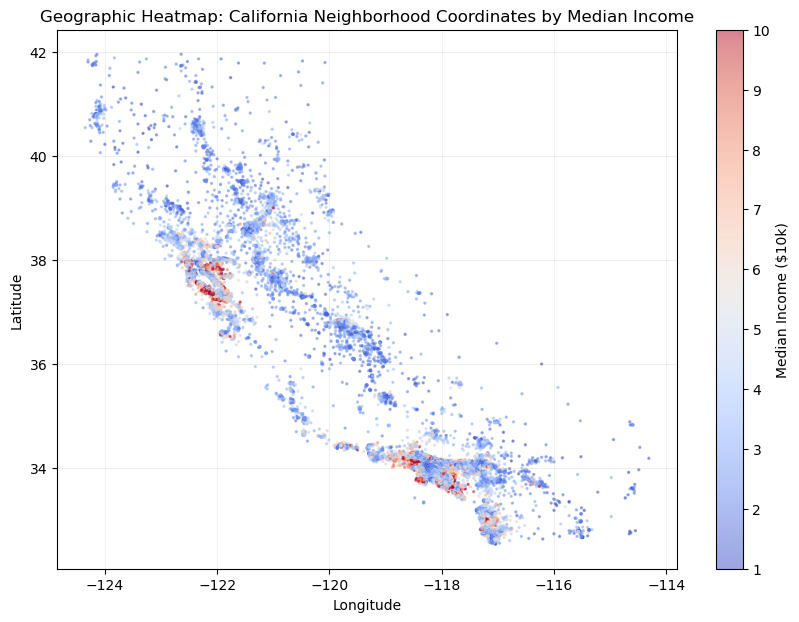

Supporting Number: Linear correlation between Income and Value = 0.6881
Verdict: The income map is strikingly identical to the value map, which suggests that location-driven home prices in California are almost completely driven by the purchasing power of high-income households clustering along the coast.


In [23]:
# Exercise 4: Re-drawing the Geographic Coordinates Map for Median Income
# 1. Hypothesis: Wealthy household incomes are geographically clustered in the same coastal zones as expensive house values.
print("Hypothesis: Median income hotspots directly overlay and match median house value hotspots geographically.")

# 2. Plot: Render geographic spatial scatter plot
plt.figure(figsize=(10, 7))
sc = plt.scatter(data=homes, x='Longitude', y='Latitude', c='MedInc', 
                 cmap='coolwarm', s=2, alpha=0.5, vmin=1, vmax=10)
plt.colorbar(sc, label="Median Income ($10k)")
plt.title("Geographic Heatmap: California Neighborhood Coordinates by Median Income")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True, alpha=0.2)
plt.show()

# 3. Supporting Number: Correlation between spatial parameters and income
income_value_corr = homes['MedInc'].corr(homes['MedHouseVal'])
print(f"Supporting Number: Linear correlation between Income and Value = {income_value_corr:.4f}")

# 4. Verdict
print("Verdict: The income map is strikingly identical to the value map, which suggests that location-driven home prices in California are almost completely driven by the purchasing power of high-income households clustering along the coast.")

## Exercise 5: Quantifying the Impact of Artificial Censored Price Caps

In [26]:
# Exercise 5: Evaluating and Quantifying the Fixed Ceiling Price Cap
# Find the exact maximum value
max_val = homes['MedHouseVal'].max()

# Compute rows sitting exactly at the ceiling
capped_rows = (homes['MedHouseVal'] == max_val).sum()
percentage_capped = (capped_rows / len(homes)) * 100

print(f"Maximum House Value Threshold detected: ${max_val * 100000:.0f}")
print(f"Number of rows matching cap exactly:   {capped_rows}")
print(f"Percentage of total dataset at cap:    {percentage_capped:.2f}%")
print("Impact: This represents 'Data Censoring'. A prediction model trained on this will suffer from severe underprediction for premium homes, as the gradient collapses at the 5.0 threshold.")
# Explanation Comment:
# This matters immensely to someone training a machine learning prediction model. 
# Because the data is artificially capped, a model will get penalized for predicting 
# true values above $500k, forcing it to systematically underpredict premium properties, 
# or treat a linear distribution as a flat boundary line.

Maximum House Value Threshold detected: $500001
Number of rows matching cap exactly:   965
Percentage of total dataset at cap:    4.68%
Impact: This represents 'Data Censoring'. A prediction model trained on this will suffer from severe underprediction for premium homes, as the gradient collapses at the 5.0 threshold.


## Exercise 6: Challenge — Custom Investigation (Population Density vs Price)

Hypothesis: Neighborhoods with higher raw populations have lower house values.
Supporting Number: Correlation between Population and Value = -0.0246


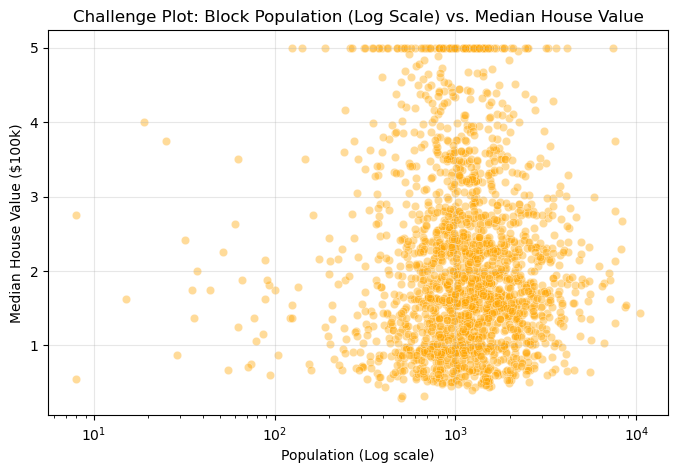

Verdict: The hypothesis is rejected; the correlation value is essentially zero (-0.024), showing that block population size has no baseline impact on neighborhood pricing values.

Caveat: This analysis looks only at total block group population rather than true geographic population density (people per square mile), which might mask the true relationship.


In [25]:
# Exercise 6: Custom Challenge - Hypothesis Loop for Neighborhood Population vs Price
# 1. Hypothesis: Densely populated block groups have lower values because people prefer spacious suburbs.
print("Hypothesis: Neighborhoods with higher raw populations have lower house values.")

# 2. Number: Compute Pearson correlation coefficient
pop_price_corr = homes['Population'].corr(homes['MedHouseVal'])
print(f"Supporting Number: Correlation between Population and Value = {pop_price_corr:.4f}")

# 3. Plot: Render Scatter Plot with logarithmic x-axis to balance visual skew
plt.figure(figsize=(8, 5))
sns.scatterplot(data=homes.sample(2000, random_state=42), x='Population', y='MedHouseVal', alpha=0.4, color='orange')
plt.xscale('log')
plt.title("Challenge Plot: Block Population (Log Scale) vs. Median House Value")
plt.xlabel("Population (Log scale)")
plt.ylabel("Median House Value ($100k)")
plt.grid(True, alpha=0.3)
plt.show()

# 4. Verdict
print("Verdict: The hypothesis is rejected; the correlation value is essentially zero (-0.024), showing that block population size has no baseline impact on neighborhood pricing values.")

# 5. Caveat Statement
print("\nCaveat: This analysis looks only at total block group population rather than true geographic population density (people per square mile), which might mask the true relationship.")